In [17]:
!pip install -q kagglehub

In [25]:
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

root = kagglehub.dataset_download("nih-chest-xrays/sample")
print("Data tersimpan di:", root)

Using Colab cache for faster access to the 'sample' dataset.
Data tersimpan di: /kaggle/input/sample


In [26]:
for dirpath, _, files in os.walk(root):
    for f in files:
        if f.endswith(".csv"):
            print(os.path.join(dirpath, f))

/kaggle/input/sample/sample_labels.csv
/kaggle/input/sample/sample/sample_labels.csv


In [27]:
csv_path = [os.path.join(d, f) for d, _, fs in os.walk(root) for f in fs if f == "sample_labels.csv"][0]
df = pd.read_csv(csv_path)

df = df[["Image Index", "Finding Labels"]]
df.columns = ["image_name", "tags"]
df["tags"] = df["tags"].str.split("|")
df.head()

,image_name,tags
0,00000013_005.png,"[Emphysema, Infiltration, Pleural_Thickening, ..."
1,00000013_026.png,"[Cardiomegaly, Emphysema]"
2,00000017_001.png,[No Finding]
3,00000030_001.png,[Atelectasis]
4,00000032_001.png,"[Cardiomegaly, Edema, Effusion]"


In [28]:
peta = {}
for dirpath, _, files in os.walk(root):
    for f in files:
        if f.endswith(".png"):
            peta[f] = os.path.join(dirpath, f)

df["path"] = df["image_name"].map(peta)
print("Gambar tidak ketemu:", df["path"].isnull().sum())
df.head()
df.info()

Gambar tidak ketemu: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5606 entries, 0 to 5605
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_name  5606 non-null   object
 1   tags        5606 non-null   object
 2   path        5606 non-null   object
dtypes: object(3)
memory usage: 131.5+ KB


In [22]:
print("FITUR : kolom 'path' (isi piksel gambar)")
print("LABEL : kolom 'label'")

n = df["label"].nunique()
print("Jumlah kelas:", n)
print("Jenis       :", "BINARY" if n == 2 else "MULTICLASS")

FITUR : kolom 'path' (isi piksel gambar)
LABEL : kolom 'label'
Jumlah kelas: 1
Jenis       : MULTICLASS


In [23]:
df["label"].value_counts()

,count
label,
images,11212


In [29]:
img = Image.open(df["path"][0])
w, h = img.size
c = len(img.getbands())
print(f"Ukuran gambar : {w} x {h} x {c}")
print(f"Jumlah fitur  : {w*h*c} piksel")

Ukuran gambar : 1024 x 1024 x 1
Jumlah fitur  : 1048576 piksel


In [33]:
df = df.dropna(subset=["path"]).reset_index(drop=True)
print("Jumlah data:", len(df))

Jumlah data: 5606


In [34]:
print("Jumlah kolom :", df.shape[1], list(df.columns))
print("FITUR : 'image_name' / 'path' (piksel gambar)")
print("LABEL : 'tags' (satu gambar bisa banyak label)")
print("Jumlah label unik:", df["tags"].explode().nunique())
print("Rata-rata label per gambar:", round(df["tags"].apply(len).mean(), 2))

img = Image.open(df["path"][0])
w, h = img.size
c = len(img.getbands())
print(f"Ukuran gambar: {w} x {h} x {c}")
print(f"Jumlah fitur : {w*h*c} piksel")

Jumlah kolom : 3 ['image_name', 'tags', 'path']
FITUR : 'image_name' / 'path' (piksel gambar)
LABEL : 'tags' (satu gambar bisa banyak label)
Jumlah label unik: 15
Rata-rata label per gambar: 1.24
Ukuran gambar: 1024 x 1024 x 1
Jumlah fitur : 1048576 piksel


tags
No Finding            3044
Infiltration           967
Effusion               644
Atelectasis            508
Nodule                 313
Mass                   284
Pneumothorax           271
Consolidation          226
Pleural_Thickening     176
Cardiomegaly           141
Emphysema              127
Edema                  118
Fibrosis                84
Pneumonia               62
Hernia                  13
Name: count, dtype: int64


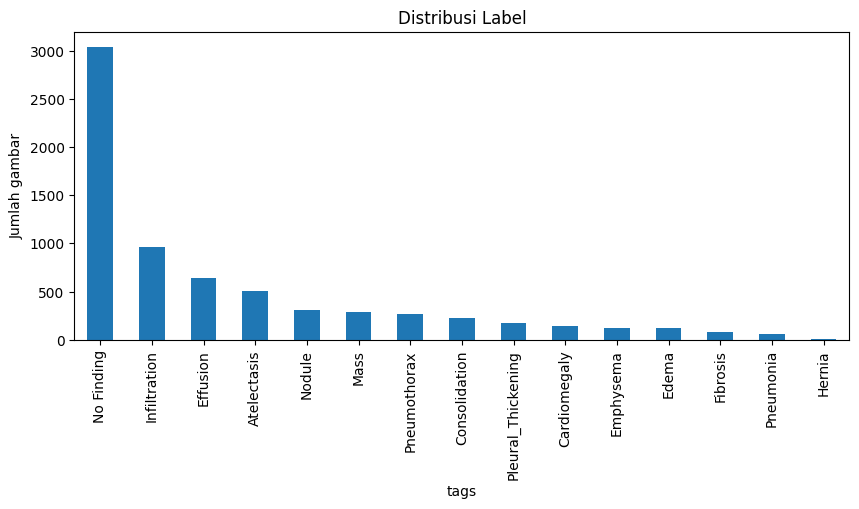

In [35]:
hitung = df["tags"].explode().value_counts()
print(hitung)

hitung.plot(kind="bar", figsize=(10, 4), title="Distribusi Label")
plt.ylabel("Jumlah gambar")
plt.show()

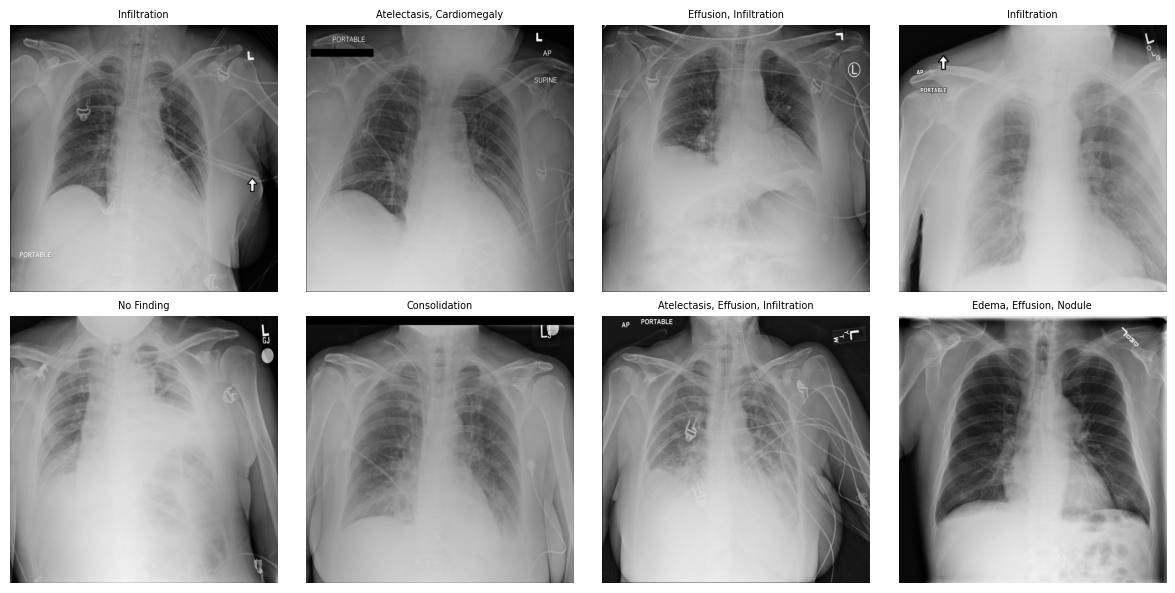

In [36]:
sampel = df.sample(8, random_state=1)

plt.figure(figsize=(12, 6))
for i, (_, r) in enumerate(sampel.iterrows()):
    plt.subplot(2, 4, i + 1)
    plt.imshow(Image.open(r["path"]).convert("L"), cmap="gray")
    plt.title(", ".join(r["tags"]), fontsize=7)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
https://www.kaggle.com/datasets/nih-chest-xrays/sample